In [1]:
# Step 1: Import Required Libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import pandas as pd
df = pd.read_csv("C:/users/sanja/Desktop/WiDS/TRAIN_NEW/TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv")
print(df.shape)
missing = df.isnull().sum().sum()
print(f"🔍 Total missing values in the dataset: {missing}")
print(df.describe())

(1213, 19901)
🔍 Total missing values in the dataset: 0
       0throw_1thcolumn  0throw_2thcolumn  0throw_3thcolumn  0throw_4thcolumn  \
count       1213.000000       1213.000000       1213.000000       1213.000000   
mean           0.185265          0.583053          0.439351          0.450398   
std            0.238481          0.172632          0.235019          0.212111   
min           -0.657053         -0.224815         -0.517318         -0.440235   
25%            0.028235          0.495514          0.286137          0.314428   
50%            0.192886          0.606585          0.469826          0.479330   
75%            0.358902          0.710758          0.626871          0.604438   
max            0.824448          0.907209          0.884576          0.876987   

       0throw_5thcolumn  0throw_6thcolumn  0throw_7thcolumn  0throw_8thcolumn  \
count       1213.000000       1213.000000       1213.000000       1213.000000   
mean           0.584654          0.554164          0.

In [3]:
df.head(10)

,participant_id,0throw_1thcolumn,0throw_2thcolumn,0throw_3thcolumn,0throw_4thcolumn,0throw_5thcolumn,0throw_6thcolumn,0throw_7thcolumn,0throw_8thcolumn,0throw_9thcolumn,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,70z8Q2xdTXM3,0.222930,0.527903,0.429966,0.060457,0.566489,0.315342,0.508408,-0.078290,0.525692,...,0.224985,0.397448,0.422966,0.184642,0.305549,0.420349,0.016328,0.561864,0.471170,0.365221
1,WHWymJu6zNZi,0.614765,0.577255,0.496127,0.496606,0.404686,0.439724,0.122590,-0.085452,0.120673,...,0.217546,-0.014549,0.000440,-0.096451,0.454501,0.343916,0.167313,0.607656,0.550623,0.503176
2,4PAQp1M6EyAo,-0.116833,0.458408,0.260703,0.639031,0.769337,0.442528,0.637110,0.192010,0.520379,...,0.342487,-0.021141,-0.037836,0.075069,0.412712,0.292708,0.391005,0.461544,0.508912,0.624232
3,obEacy4Of68I,0.199688,0.752714,0.658283,0.575096,0.692867,0.645789,0.522750,0.412188,0.530843,...,0.103562,-0.178313,0.210983,-0.018666,0.436313,0.592982,0.216205,0.341272,0.440313,0.558193
4,s7WzzDcmDOhF,0.227321,0.613268,0.621447,0.562673,0.736709,0.589813,0.266676,0.359668,0.300771,...,-0.164956,0.007064,-0.120904,-0.488095,0.493575,-0.215361,0.210685,0.055850,0.119065,0.108273
5,s55ZRHrJtnlL,0.337316,0.823123,0.733585,0.418883,0.771445,0.653699,0.693189,0.345408,0.729822,...,0.119869,0.047217,0.139147,0.187316,0.534683,0.175817,0.291163,0.569374,0.737414,0.716293
6,sId1cQF5F22m,0.205613,0.514554,0.580002,0.356749,0.355509,0.402521,0.503667,-0.090709,0.442115,...,-0.068885,-0.288361,-0.259806,-0.072032,0.395912,0.340496,0.217748,0.408298,0.174187,0.659205
7,T4CaImRntWnB,-0.190693,0.311654,0.309758,0.466017,0.461799,0.348240,0.258351,0.267011,0.204740,...,0.011235,0.172349,0.099238,0.324650,0.266663,0.262601,0.096195,0.497883,0.617897,0.555232
8,a5JFxSZjVg5i,0.243401,0.274912,0.364787,0.252179,0.645695,0.677565,0.480189,0.400882,0.407494,...,-0.057347,-0.161009,-0.156577,-0.081074,0.767887,0.607772,0.241883,0.708180,0.247329,0.452594
9,VZnIq2hRErI5,0.182886,0.734523,0.286137,0.300662,0.542568,0.707586,0.646182,0.263905,0.554053,...,0.032387,0.407388,0.328920,0.364869,0.569350,0.266910,0.458811,0.567601,0.723238,0.547051


In [4]:
df.tail(10)

,participant_id,0throw_1thcolumn,0throw_2thcolumn,0throw_3thcolumn,0throw_4thcolumn,0throw_5thcolumn,0throw_6thcolumn,0throw_7thcolumn,0throw_8thcolumn,0throw_9thcolumn,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
1203,HNjDLTaifDI2,0.022649,0.324982,0.451550,0.600290,0.692237,0.629771,0.565231,0.440082,0.428669,...,-0.088996,-0.192461,-0.165782,-0.150046,0.090972,0.104193,0.069348,0.229821,0.226734,0.596179
1204,kTurROKp5YHQ,0.348020,0.749632,0.378984,0.622881,0.703211,0.720762,0.701220,0.437297,0.653208,...,0.062865,-0.056259,0.111638,0.042620,0.490007,0.032003,0.408853,0.206432,0.668807,0.304231
1205,FCRyMz9O6yCq,0.071400,0.697010,0.673969,0.689061,0.823189,0.679552,0.530139,0.289084,0.407226,...,-0.108867,-0.184437,-0.185079,-0.285433,0.488431,0.353709,0.167194,0.587768,0.178675,0.455333
1206,vm2P1hmAY1hl,0.462948,0.851463,0.638908,0.542838,0.790042,0.599957,0.519429,0.197866,0.622234,...,-0.138053,-0.035717,-0.090862,0.034485,0.741929,0.630786,0.548605,0.653903,0.364794,0.519091
1207,OFxvN8lnw21w,0.082061,0.515127,0.401326,-0.016466,0.257117,0.645803,0.495707,0.345426,0.344817,...,0.048837,-0.254591,-0.238310,-0.077425,0.452512,0.174771,0.144817,0.582412,0.406782,0.720198
1208,9gpepMI9sj5q,0.265284,0.551726,0.628318,0.647700,0.710757,0.132334,0.326207,0.354319,0.531170,...,0.127097,0.129787,0.298987,0.114577,0.534109,0.118893,0.181292,0.181055,0.238357,0.577009
1209,FIDen5rdMc0v,-0.018377,0.576689,0.527451,0.327463,0.586868,0.573689,0.300544,0.301103,0.659840,...,0.482214,-0.159587,-0.162498,-0.093249,0.309914,0.143818,0.218337,0.389331,0.328741,0.238443
1210,dlsMC4TXL4e8,0.227028,0.405659,0.023545,-0.093085,-0.068960,0.647574,0.762552,0.465109,0.199337,...,-0.379304,0.126976,0.193695,0.214483,0.429836,0.302141,0.104774,0.856375,0.303248,0.363639
1211,syeyZjEx8FUx,0.189849,0.752876,0.842463,0.817037,0.820196,0.792950,0.650929,0.488504,0.580207,...,-0.212254,-0.055539,-0.221935,-0.202464,0.602651,0.482066,0.399363,0.373746,0.279900,0.684434
1212,wWZUoBUOOXhT,0.165500,0.779444,0.686992,0.723378,0.747767,0.616990,0.513525,0.301234,0.392071,...,-0.185250,-0.290530,-0.276083,-0.384149,0.626095,0.664824,0.587586,0.704292,0.799295,0.653542


C:\Users\sanja\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


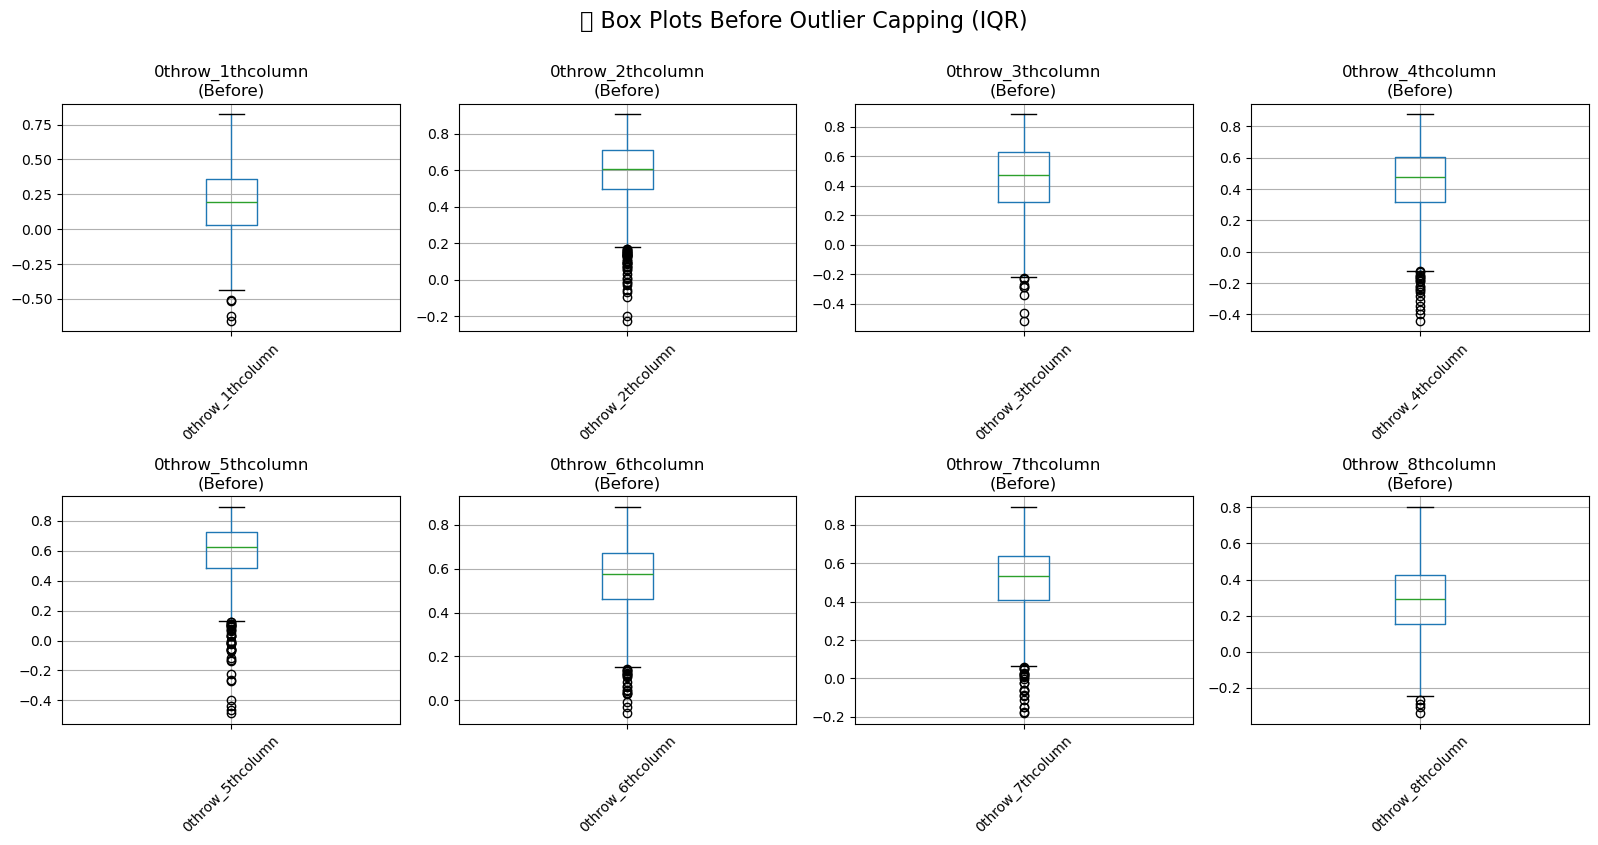

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 0: Select only numeric columns from your main DataFrame
df_numeric = df.select_dtypes(include='number')

# Step 1: Pick the first 8 numeric columns for visualization
example_cols = df_numeric.columns[:8]

# Step 2: Boxplots BEFORE outlier capping (2 rows x 4 columns)
plt.figure(figsize=(16, 8))
for i, col in enumerate(example_cols):
    plt.subplot(2, 4, i + 1)
    df_numeric.boxplot(column=col)
    plt.title(f'{col}\n(Before)')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.suptitle("📦 Box Plots Before Outlier Capping (IQR)", fontsize=16, y=1.05)
plt.show()



In [6]:
# Descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
0throw_1thcolumn,1213.0,0.185265,0.238481,-0.657053,0.028235,0.192886,0.358902,0.824448
0throw_2thcolumn,1213.0,0.583053,0.172632,-0.224815,0.495514,0.606585,0.710758,0.907209
0throw_3thcolumn,1213.0,0.439351,0.235019,-0.517318,0.286137,0.469826,0.626871,0.884576
0throw_4thcolumn,1213.0,0.450398,0.212111,-0.440235,0.314428,0.479330,0.604438,0.876987
0throw_5thcolumn,1213.0,0.584654,0.195918,-0.486239,0.486735,0.623346,0.726116,0.893974
...,...,...,...,...,...,...,...,...
196throw_198thcolumn,1213.0,0.376624,0.197995,-0.359869,0.262601,0.391739,0.521904,0.866371
196throw_199thcolumn,1213.0,0.370711,0.191249,-0.553067,0.242569,0.388528,0.505970,0.828784
197throw_198thcolumn,1213.0,0.500415,0.177047,-0.302408,0.389078,0.524508,0.630443,0.914021
197throw_199thcolumn,1213.0,0.476418,0.177732,-0.307228,0.367971,0.496103,0.600065,0.898459


In [7]:
df['participant_id'] = df['participant_id'].astype(str).str.strip()

In [8]:
import pandas as pd

def cap_outliers_iqr(df, factor=1.5):
    df_capped = df.copy()
    for col in df_capped.select_dtypes(include='number').columns:
        Q1 = df_capped[col].quantile(0.25)
        Q3 = df_capped[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - factor * IQR
        upper_bound = Q3 + factor * IQR
        df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)
    return df_capped

# Example: assuming your original DataFrame is named 'df'
df_capped = cap_outliers_iqr(df)  # Replace 'df' with your dataset


C:\Users\sanja\AppData\Local\Temp\ipykernel_5480\2752334077.py:16: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


<Figure size 1600x1000 with 0 Axes>

C:\Users\sanja\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


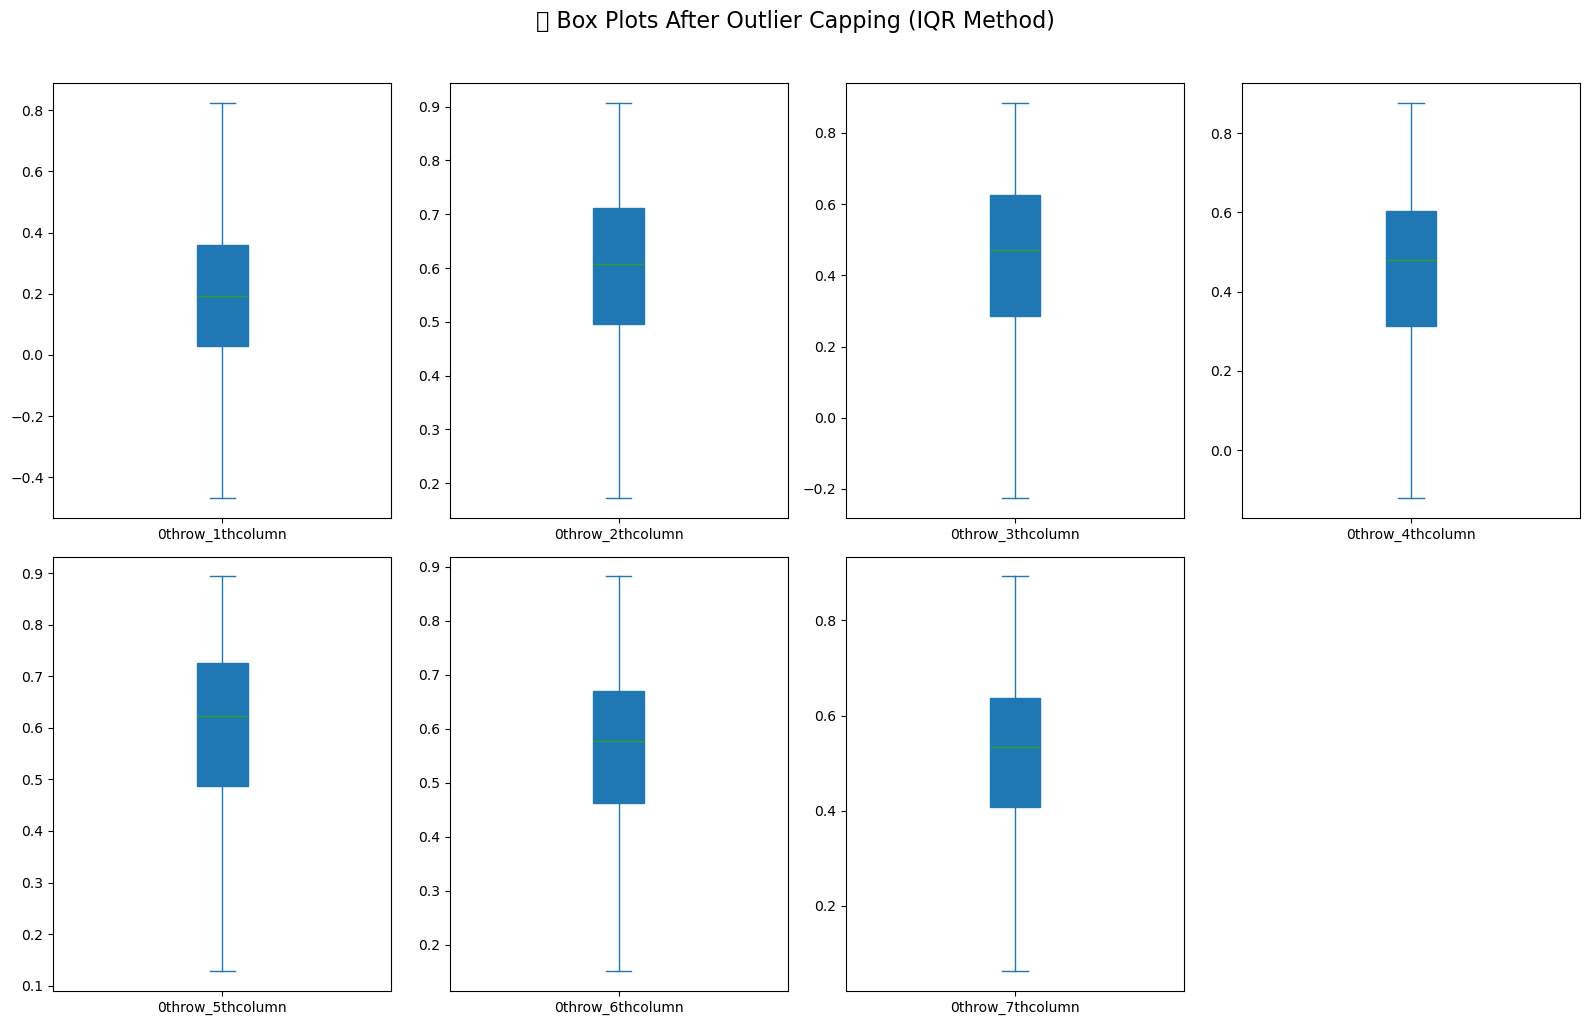

In [9]:
import matplotlib.pyplot as plt

# Pick the same 8 columns used earlier or adjust as needed
example_cols = df_capped.columns[:8]

# Boxplot AFTER Outlier Capping with 2x4 layout
plt.figure(figsize=(16, 10))
df_capped[example_cols].plot(
    kind='box',
    subplots=True,
    layout=(2, 4),  # 2 rows, 4 columns
    figsize=(16, 10),
    patch_artist=True
)
plt.suptitle("📦 Box Plots After Outlier Capping (IQR Method)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


In [10]:
from sklearn.impute import KNNImputer

if df.isnull().sum().sum() > 0:
    imputer = KNNImputer(n_neighbors=5)
    numeric_cols = df.select_dtypes('number').columns
    df[numeric_cols] = imputer.fit_transform(df[numeric_cols])


**Purpose:**
In functional connectome datasets, the numerical features typically represent correlation coefficients between brain regions, which should theoretically range from -1 to 1. Values outside this range can arise due to preprocessing artifacts or data corruption.

**Justification:**
Clipping ensures that all numerical features remain within the mathematically valid range for correlations. This preserves the interpretability and correctness of the data.

**Effect:**
Any value below -1 is set to -1, and any value above 1 is set to 1, thereby enforcing valid correlation values and reducing noise from invalid extremes.

In [11]:
# Backup original DataFrame before outlier removal
df_original = df.copy()

In [12]:
df[df.select_dtypes('number').columns] = df.select_dtypes('number').clip(-1, 1)

**Purpose:**
Duplicate columns can arise during data merging or feature generation and offer no additional information for modeling.

**Justification:**
Removing duplicate features prevents multicollinearity and reduces computational overhead. It also improves model generalizability by eliminating redundant information.

**Effect:**
The dimensionality of the dataset is reduced by removing columns with identical values. This helps streamline the dataset without loss of unique information.

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
features = df.select_dtypes('number').columns
scaled = scaler.fit_transform(df[features])
scaled_df = pd.DataFrame(scaled, columns=features)
scaled_df['participant_id'] = df['participant_id']


**Purpose:**
Standardization rescales features to have a mean of 0 and a standard deviation of 1.

**Justification:**
Many machine learning algorithms (e.g., PCA, K-Means, SVM) are sensitive to the scale of features. Standardizing ensures that each feature contributes equally, preventing dominance by features with larger numerical ranges.

**Effect:**
All numeric features are transformed to a common scale, facilitating improved model performance and better convergence behavior during training.

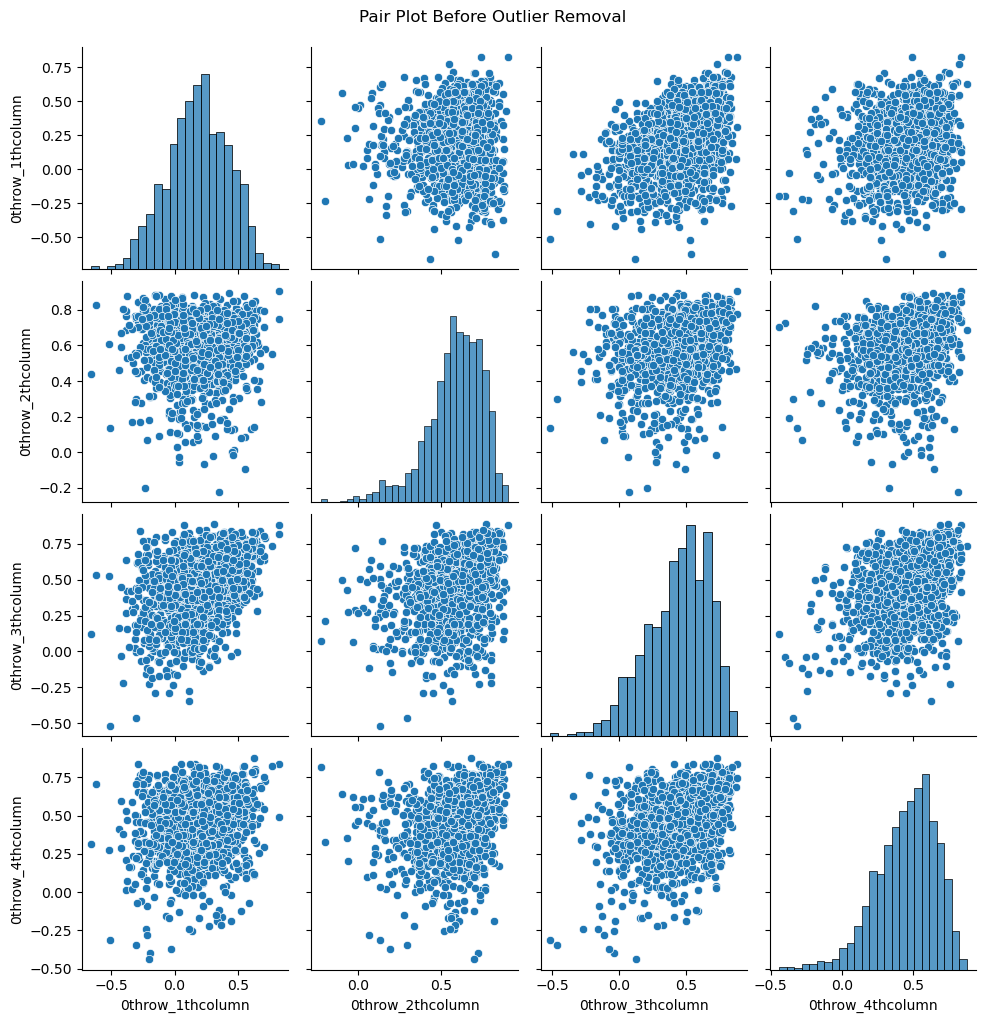

In [14]:
# Pair Plot BEFORE outlier removal
sns.pairplot(df_original.iloc[:, :5])  # Adjust number of columns as needed
plt.suptitle("Pair Plot Before Outlier Removal", y=1.02)
plt.show()

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
pca_features = pca.fit_transform(scaled_df[features])
reduced_df = pd.DataFrame(pca_features, columns=[f'PC_{i+1}' for i in range(pca_features.shape[1])])
reduced_df['participant_id'] = df['participant_id']


**Purpose:**
Principal Component Analysis (PCA) is used to reduce the number of features while retaining most of the variance (information) in the dataset.

**Justification:**
High-dimensional data (such as connectome matrices) can lead to overfitting and computational inefficiencies. PCA helps in reducing redundancy and uncovering the underlying structure by projecting the data onto a set of orthogonal components that explain 95% of the variance.

**Effect:**
The original features are transformed into a smaller set of principal components (PCs), significantly reducing dimensionality while preserving the most important patterns in the data.

In [16]:
#Quality Control Function
def quality_control_checks(df):
    return {
        "Missing Values": df.isnull().sum().sum(),
        "Value Range": {
            "Min": df.min().min(),
            "Max": df.max().max()
        },
        "Number of Features": df.shape[1],
        "Number of Samples": df.shape[0]
    }

initial_checks = quality_control_checks(df_numeric)

**Purpose:**
To evaluate the structural and statistical integrity of the dataset by summarizing critical metrics such as missing values, value range, number of features, and number of samples.

**Justification:**
Ensuring data quality is a fundamental prerequisite before applying any machine learning or statistical modeling. Missing values can disrupt computations, out-of-range values may indicate data corruption, and unexpected changes in the number of features or samples can signal errors introduced during preprocessing steps such as merging, filtering, or transformation.

**Effect:**
Provides a concise and interpretable summary of the dataset’s health at any stage of the pipeline. This facilitates early detection of anomalies, supports reproducibility, and ensures that the data is clean, consistent, and suitable for downstream analysis and modeling.

In [17]:
# Save reduced dataset
reduced_df.to_csv('preprocessed_connectome_data.csv', index=False)

# Save preprocessing parameters for reproducibility
preprocessing_params = {
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(),
    'pca_components': pca.components_.tolist(),
    'pca_explained_variance_ratio': pca.explained_variance_ratio_.tolist()
}


In [18]:
preprocessing_report = {
    'Initial Shape': df_numeric.shape,
    'Final Shape': reduced_df.shape,
    'Missing Values Handled': initial_checks['Missing Values'],
    'PCA Components Retained': reduced_df.shape[1] - 1,  # Excluding participant_id
    'Total Variance Explained': sum(pca.explained_variance_ratio_)
}
print(preprocessing_report)


{'Initial Shape': (1213, 19900), 'Final Shape': (1213, 910), 'Missing Values Handled': np.int64(0), 'PCA Components Retained': 909, 'Total Variance Explained': np.float64(0.9500967625371134)}


**Initial Shape  :	(1213, 19900)**	

We started with 1,213 samples and 19,900 connectome features .

**Final Shape	 :  (1213, 910)**

After PCA, the dataset has been reduced to 910 features (principal components), which is a 95% reduction in dimensionality while preserving variance.

**Missing Values Handled :	0**	

There were no missing values, or they were successfully imputed beforehand.	

**PCA retained 909 components out of 19,900** 

This means  data is very high-dimensional, but PCA was able to reduce it significantly while retaining info.

**Total Variance Explained	95.01%**

We're preserving 95% of the original information, which is excellent for modeling and analysis.

In [19]:
import pandas as pd

# Load the dataset
reduced_df = pd.read_csv('preprocessed_connectome_data.csv')

# View the head and tail of the dataset
head_data = reduced_df.head()
tail_data = reduced_df.tail()

head_data, tail_data

(        PC_1       PC_2       PC_3       PC_4       PC_5       PC_6  \
 0  35.753597   0.090543 -20.350098  19.088315 -30.805000   2.306746   
 1  28.459455 -18.887916  10.232790   1.115161  -7.235638 -14.893705   
 2   0.798687   4.718468  10.989505 -17.687384  10.643912  31.792714   
 3 -45.767171 -11.453186   4.095472  12.695696 -20.976370  22.331782   
 4   3.746646  -8.847485  10.058838  -2.305610  -3.341812  14.484016   
 
         PC_7       PC_8       PC_9      PC_10  ...    PC_901    PC_902  \
 0  -0.012355 -16.080110  -6.713655   7.132238  ... -1.867458  0.202470   
 1  -5.991655  -3.274425 -18.623446 -12.154646  ... -0.135854  1.095068   
 2   9.804087  16.585635 -15.010728  -8.778202  ...  0.200789  2.164244   
 3  -4.630708  -4.709863   0.145218  10.252135  ...  4.576554  2.859549   
 4 -28.106098   5.519340  -6.920033   4.655665  ...  1.482503 -2.051239   
 
      PC_903    PC_904    PC_905    PC_906    PC_907    PC_908    PC_909  \
 0 -0.807275 -1.052922  1.631162 -5.56

In [20]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213 entries, 0 to 1212
Columns: 19901 entries, participant_id to 198throw_199thcolumn
dtypes: float64(19900), object(1)
memory usage: 184.2+ MB


In [21]:
# Count how many values were capped in each column
capped_counts = (df_original != df).sum()

# Filter out columns where no capping was done
non_zero_capped = capped_counts[capped_counts > 0]

# Check if there are any capped values to plot
if not non_zero_capped.empty:
    plt.figure(figsize=(12, 5))
    non_zero_capped.sort_values(ascending=False).plot(kind='bar', color='coral')
    plt.title('Number of Capped Outliers per Feature')
    plt.ylabel('Count of Capped Values')
    plt.xlabel('Feature')
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()
else:
    print("✅ No outliers were capped in any feature.")


✅ No outliers were capped in any feature.


In [22]:
import pandas as pd

# Load datasets
raw_df = pd.read_csv("C:/Users/sanja/Desktop/WiDS/TRAIN_NEW/TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv")
preprocessed_df = pd.read_csv("preprocessed_connectome_data.csv")

# Summary of comparison
print("🔍 Dataset Shape:")
print(f"Raw Dataset Shape: {raw_df.shape}")
print(f"Preprocessed Dataset Shape: {preprocessed_df.shape}\n")

print("🧹 Null Value Check:")
print(f"Raw Dataset Null Values: {raw_df.isnull().sum().sum()}")
print(f"Preprocessed Dataset Null Values: {preprocessed_df.isnull().sum().sum()}\n")

print("📑 Duplicate Row Check:")
print(f"Raw Dataset Duplicates: {raw_df.duplicated().sum()}")
print(f"Preprocessed Dataset Duplicates: {preprocessed_df.duplicated().sum()}\n")

print("📋 First 5 Columns (Raw):", raw_df.columns[:5].tolist())
print("📋 First 5 Columns (Preprocessed):", preprocessed_df.columns[:5].tolist(), "\n")

print("🔎 Sample Rows from Raw Dataset:")
display(raw_df.head())

print("🔎 Sample Rows from Preprocessed Dataset:")
display(preprocessed_df.head())


🔍 Dataset Shape:
Raw Dataset Shape: (1213, 19901)
Preprocessed Dataset Shape: (1213, 910)

🧹 Null Value Check:
Raw Dataset Null Values: 0
Preprocessed Dataset Null Values: 0

📑 Duplicate Row Check:
Raw Dataset Duplicates: 0
Preprocessed Dataset Duplicates: 0

📋 First 5 Columns (Raw): ['participant_id', '0throw_1thcolumn', '0throw_2thcolumn', '0throw_3thcolumn', '0throw_4thcolumn']
📋 First 5 Columns (Preprocessed): ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5'] 

🔎 Sample Rows from Raw Dataset:


,participant_id,0throw_1thcolumn,0throw_2thcolumn,0throw_3thcolumn,0throw_4thcolumn,0throw_5thcolumn,0throw_6thcolumn,0throw_7thcolumn,0throw_8thcolumn,0throw_9thcolumn,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,70z8Q2xdTXM3,0.222930,0.527903,0.429966,0.060457,0.566489,0.315342,0.508408,-0.078290,0.525692,...,0.224985,0.397448,0.422966,0.184642,0.305549,0.420349,0.016328,0.561864,0.471170,0.365221
1,WHWymJu6zNZi,0.614765,0.577255,0.496127,0.496606,0.404686,0.439724,0.122590,-0.085452,0.120673,...,0.217546,-0.014549,0.000440,-0.096451,0.454501,0.343916,0.167313,0.607656,0.550623,0.503176
2,4PAQp1M6EyAo,-0.116833,0.458408,0.260703,0.639031,0.769337,0.442528,0.637110,0.192010,0.520379,...,0.342487,-0.021141,-0.037836,0.075069,0.412712,0.292708,0.391005,0.461544,0.508912,0.624232
3,obEacy4Of68I,0.199688,0.752714,0.658283,0.575096,0.692867,0.645789,0.522750,0.412188,0.530843,...,0.103562,-0.178313,0.210983,-0.018666,0.436313,0.592982,0.216205,0.341272,0.440313,0.558193
4,s7WzzDcmDOhF,0.227321,0.613268,0.621447,0.562673,0.736709,0.589813,0.266676,0.359668,0.300771,...,-0.164956,0.007064,-0.120904,-0.488095,0.493575,-0.215361,0.210685,0.055850,0.119065,0.108273


🔎 Sample Rows from Preprocessed Dataset:


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10,...,PC_901,PC_902,PC_903,PC_904,PC_905,PC_906,PC_907,PC_908,PC_909,participant_id
0,35.753597,0.090543,-20.350098,19.088315,-30.805000,2.306746,-0.012355,-16.080110,-6.713655,7.132238,...,-1.867458,0.202470,-0.807275,-1.052922,1.631162,-5.564914,0.997390,2.484893,2.336370,70z8Q2xdTXM3
1,28.459455,-18.887916,10.232790,1.115161,-7.235638,-14.893705,-5.991655,-3.274425,-18.623446,-12.154646,...,-0.135854,1.095068,2.677866,1.209573,-0.033705,-0.855254,-0.299215,0.106578,-1.821413,WHWymJu6zNZi
2,0.798687,4.718468,10.989505,-17.687384,10.643912,31.792714,9.804087,16.585635,-15.010728,-8.778202,...,0.200789,2.164244,-3.524307,3.650027,-2.614596,-0.126338,-3.130259,-4.157327,-3.099733,4PAQp1M6EyAo
3,-45.767171,-11.453186,4.095472,12.695696,-20.976370,22.331782,-4.630708,-4.709863,0.145218,10.252135,...,4.576554,2.859549,0.963681,-0.298823,1.421169,2.988568,2.193247,0.690774,-3.252614,obEacy4Of68I
4,3.746646,-8.847485,10.058838,-2.305610,-3.341812,14.484016,-28.106098,5.519340,-6.920033,4.655665,...,1.482503,-2.051239,0.382910,-0.810435,-3.369483,1.600956,-5.888159,-0.133083,2.126439,s7WzzDcmDOhF


**Data Visualization**

In [23]:
import pandas as pd

# Load the preprocessed dataset
df = pd.read_csv("preprocessed_connectome_data.csv")

# Quick check
print("Shape:", df.shape)
df.head()


Shape: (1213, 910)


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10,...,PC_901,PC_902,PC_903,PC_904,PC_905,PC_906,PC_907,PC_908,PC_909,participant_id
0,35.753597,0.090543,-20.350098,19.088315,-30.805000,2.306746,-0.012355,-16.080110,-6.713655,7.132238,...,-1.867458,0.202470,-0.807275,-1.052922,1.631162,-5.564914,0.997390,2.484893,2.336370,70z8Q2xdTXM3
1,28.459455,-18.887916,10.232790,1.115161,-7.235638,-14.893705,-5.991655,-3.274425,-18.623446,-12.154646,...,-0.135854,1.095068,2.677866,1.209573,-0.033705,-0.855254,-0.299215,0.106578,-1.821413,WHWymJu6zNZi
2,0.798687,4.718468,10.989505,-17.687384,10.643912,31.792714,9.804087,16.585635,-15.010728,-8.778202,...,0.200789,2.164244,-3.524307,3.650027,-2.614596,-0.126338,-3.130259,-4.157327,-3.099733,4PAQp1M6EyAo
3,-45.767171,-11.453186,4.095472,12.695696,-20.976370,22.331782,-4.630708,-4.709863,0.145218,10.252135,...,4.576554,2.859549,0.963681,-0.298823,1.421169,2.988568,2.193247,0.690774,-3.252614,obEacy4Of68I
4,3.746646,-8.847485,10.058838,-2.305610,-3.341812,14.484016,-28.106098,5.519340,-6.920033,4.655665,...,1.482503,-2.051239,0.382910,-0.810435,-3.369483,1.600956,-5.888159,-0.133083,2.126439,s7WzzDcmDOhF


**Visualizations With Outliers**

**1.1.Pair Plot**

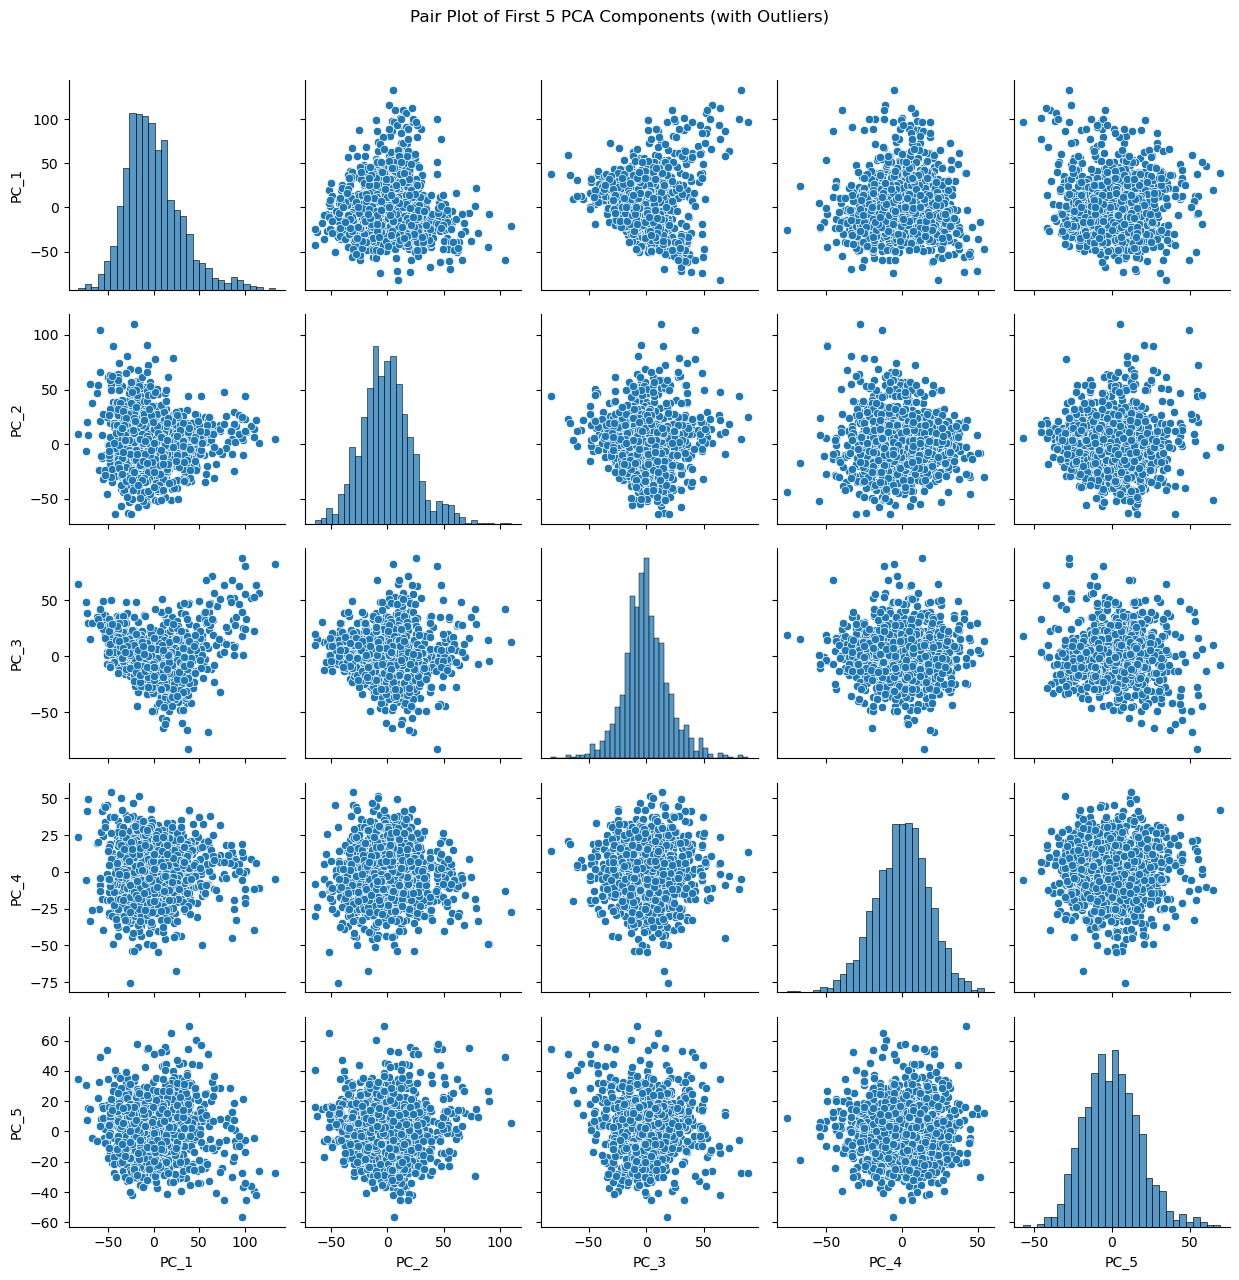

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

pca_cols = [col for col in df.columns if col.startswith('PC_')][:5]
sns.pairplot(df[pca_cols])
plt.suptitle("Pair Plot of First 5 PCA Components (with Outliers)", y=1.02)
plt.tight_layout()
plt.show()


**1.2. Correlation Heatmap**

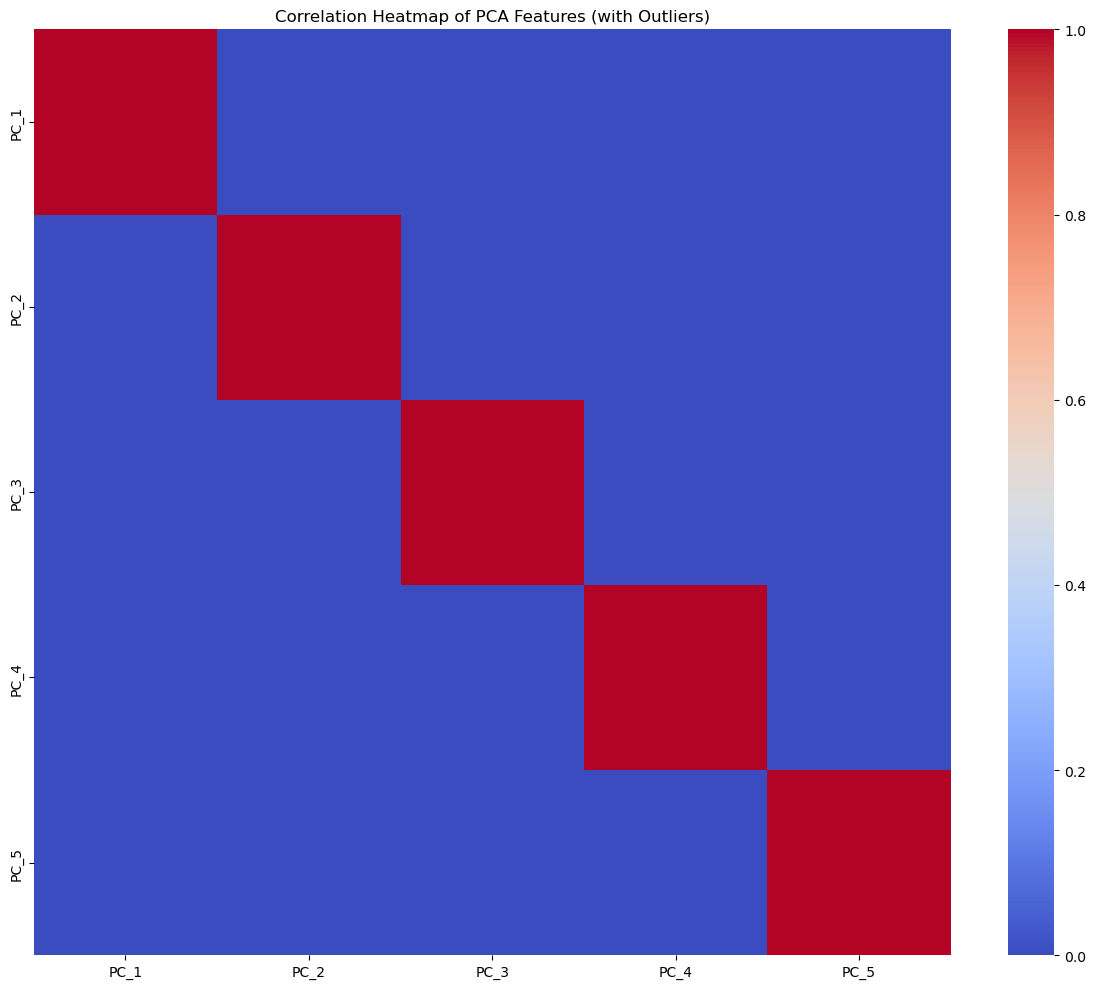

In [25]:
corr_matrix = df[pca_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap of PCA Features (with Outliers)")
plt.tight_layout()
plt.show()


**1.3. Histograms**

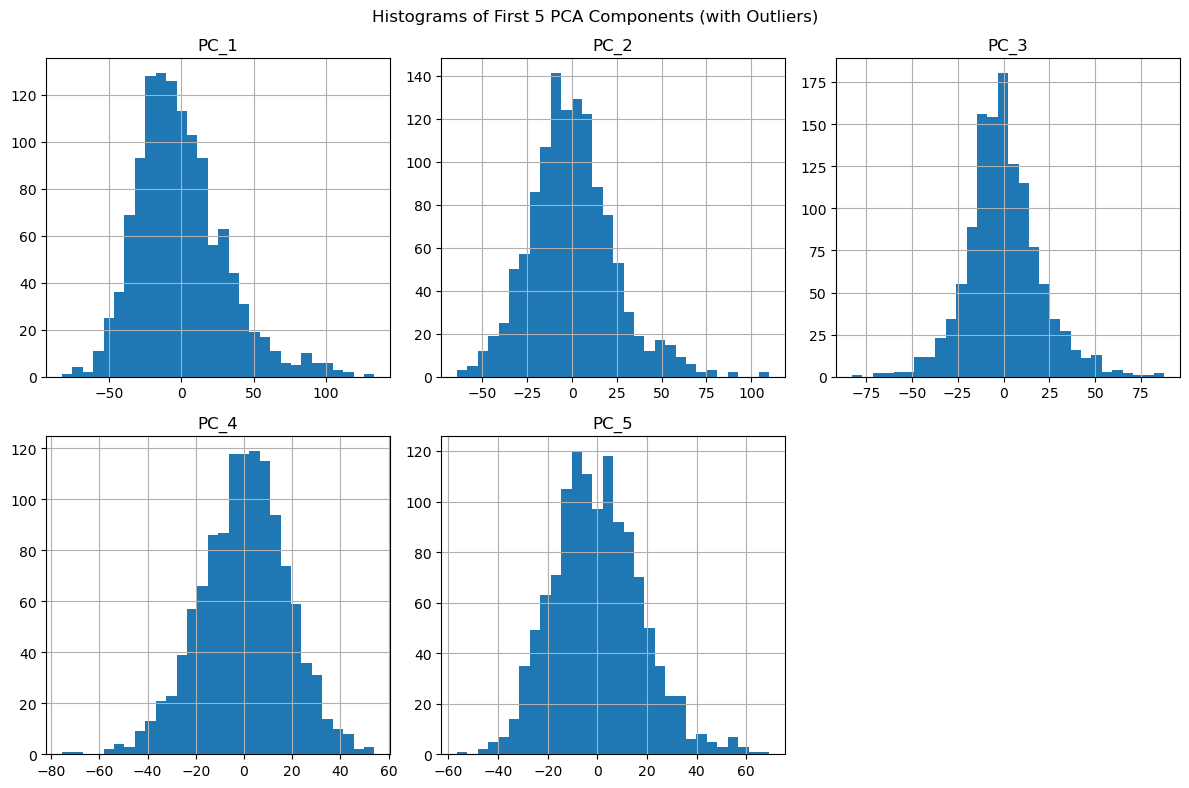

In [26]:
df[pca_cols[:5]].hist(bins=30, figsize=(12, 8), layout=(2, 3))
plt.suptitle("Histograms of First 5 PCA Components (with Outliers)")
plt.tight_layout()
plt.show()


**1.4 Boxplot**

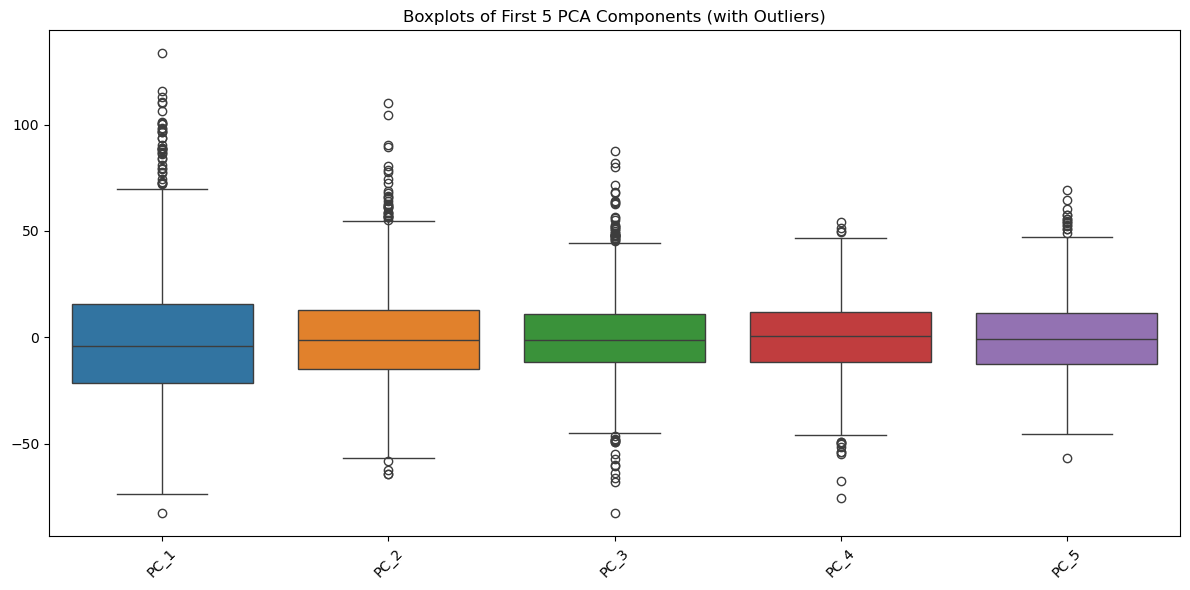

In [27]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[pca_cols[:5]])
plt.title("Boxplots of First 5 PCA Components (with Outliers)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Remove Outliers**

In [28]:
from scipy.stats import zscore
import numpy as np

df_zscores = df[pca_cols].apply(zscore)
mask = (np.abs(df_zscores) < 3).all(axis=1)
df_clean = df[mask].reset_index(drop=True)

print(f"Original shape: {df.shape}")
print(f"After outlier removal: {df_clean.shape}")


Original shape: (1213, 910)
After outlier removal: (1166, 910)


**Visualizations Without Outliers**

**2.1 Pair Plot**

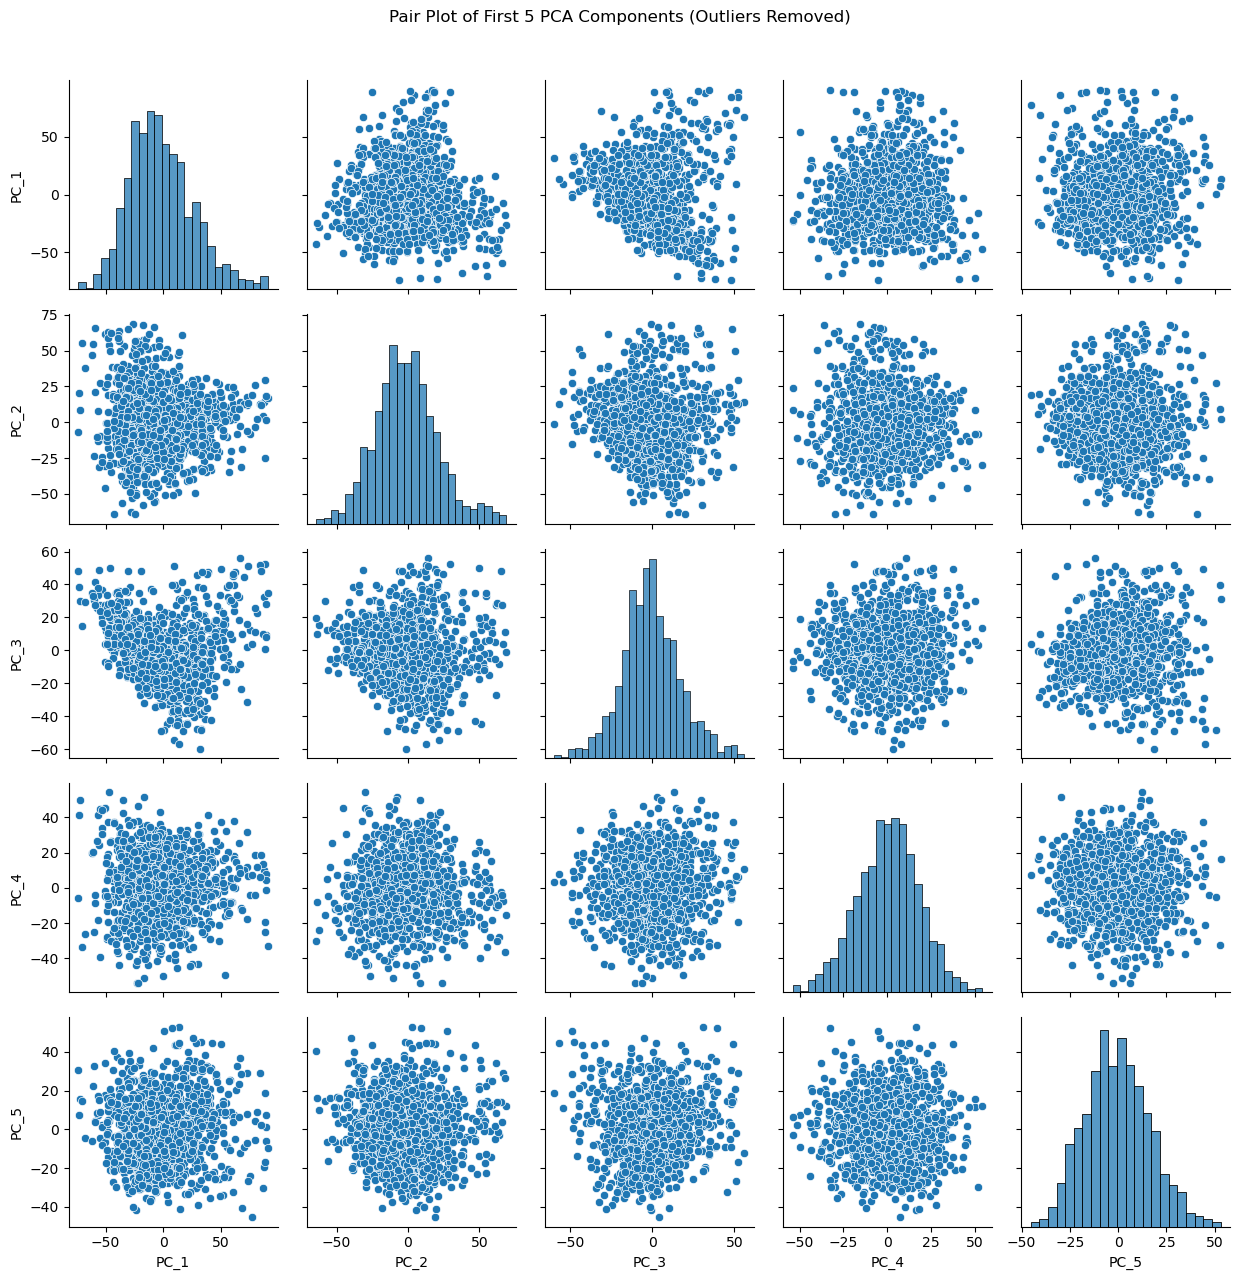

In [29]:
sns.pairplot(df_clean[pca_cols[:5]])
plt.suptitle("Pair Plot of First 5 PCA Components (Outliers Removed)", y=1.02)
plt.tight_layout()
plt.show()


**2.2 Correlation Heatmap**

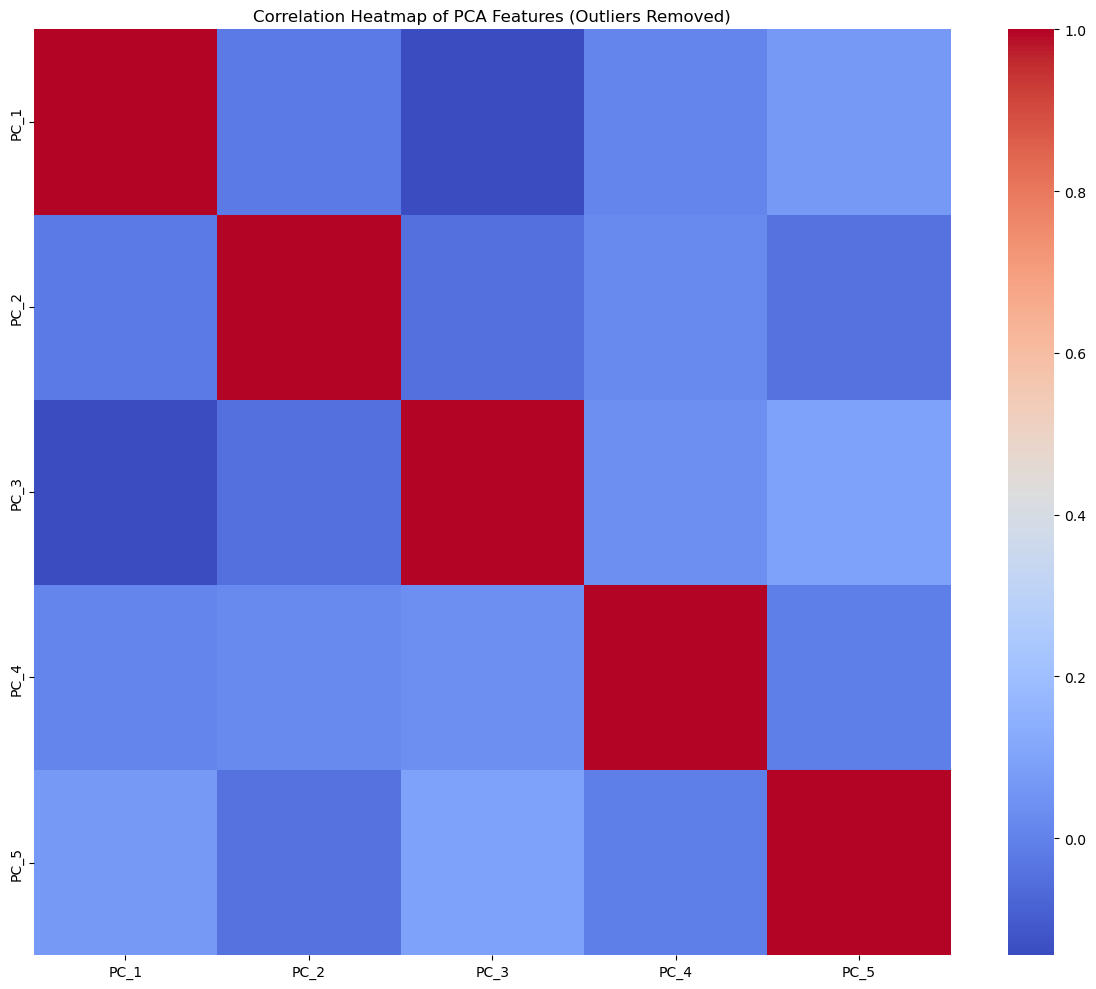

In [30]:
corr_matrix_clean = df_clean[pca_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_clean, cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap of PCA Features (Outliers Removed)")
plt.tight_layout()
plt.show()


**2.3.Histograms (No Outliers)**

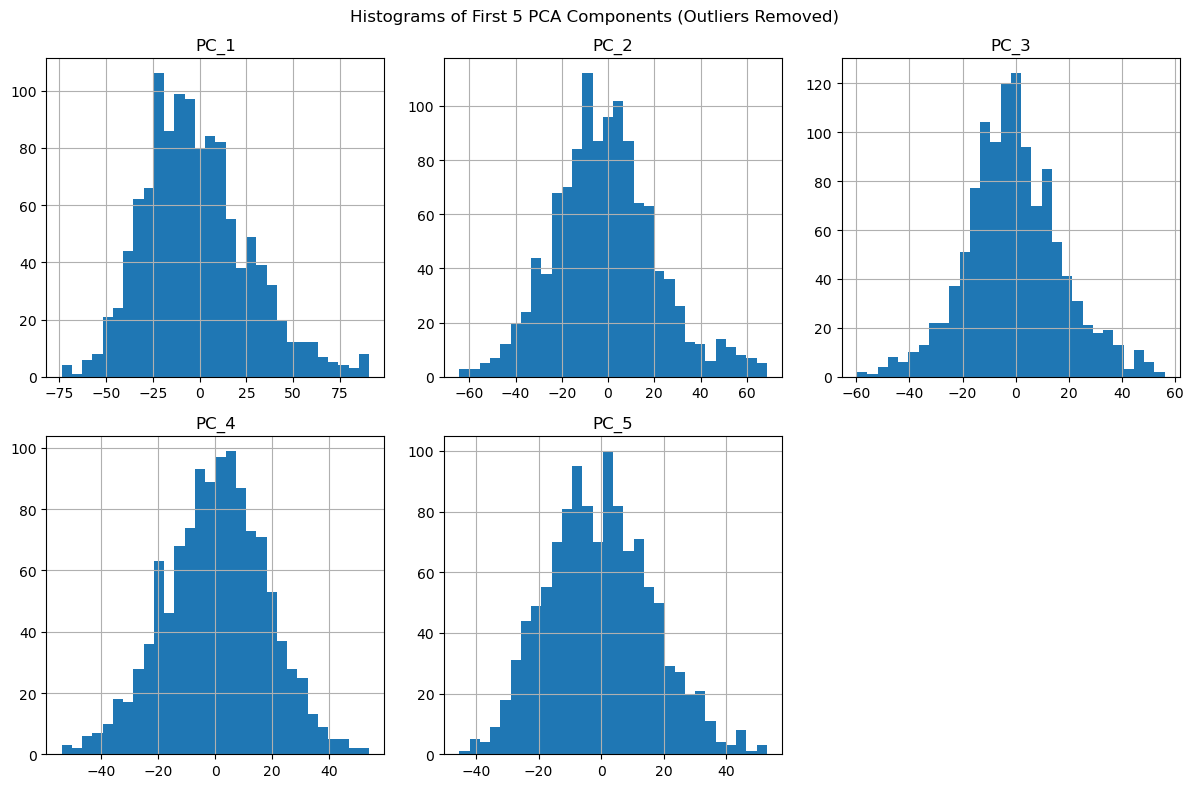

In [31]:
df_clean[pca_cols[:5]].hist(bins=30, figsize=(12, 8), layout=(2, 3))
plt.suptitle("Histograms of First 5 PCA Components (Outliers Removed)")
plt.tight_layout()
plt.show()


**2.4 Boxplots (No Outliers)**

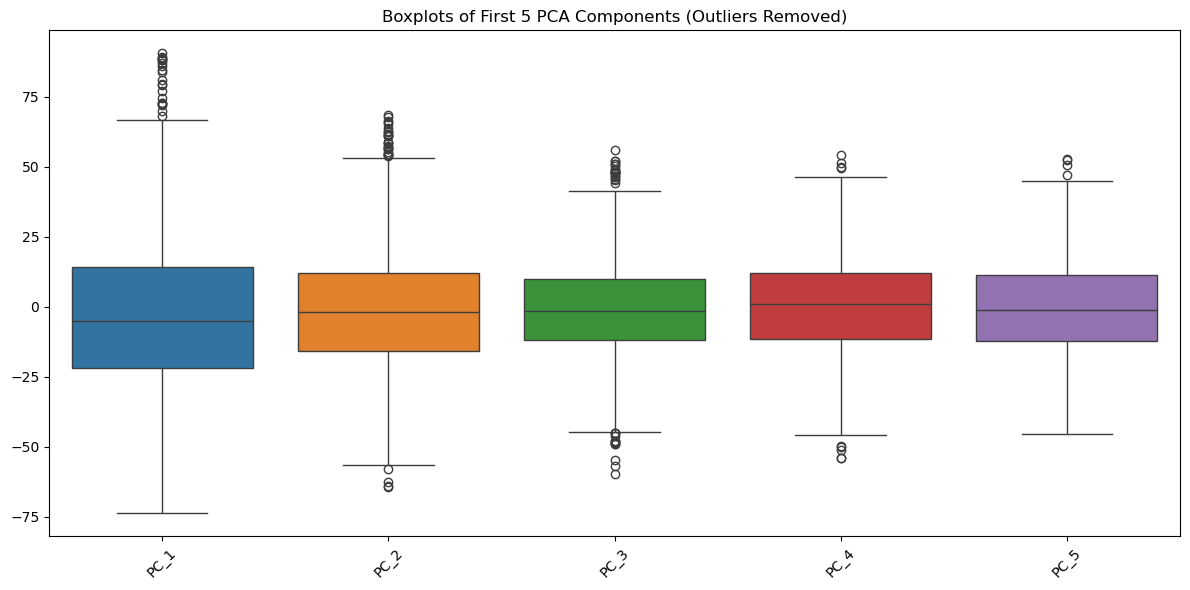

In [32]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[pca_cols[:5]])
plt.title("Boxplots of First 5 PCA Components (Outliers Removed)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**PCA Scatter Plot (2D)**

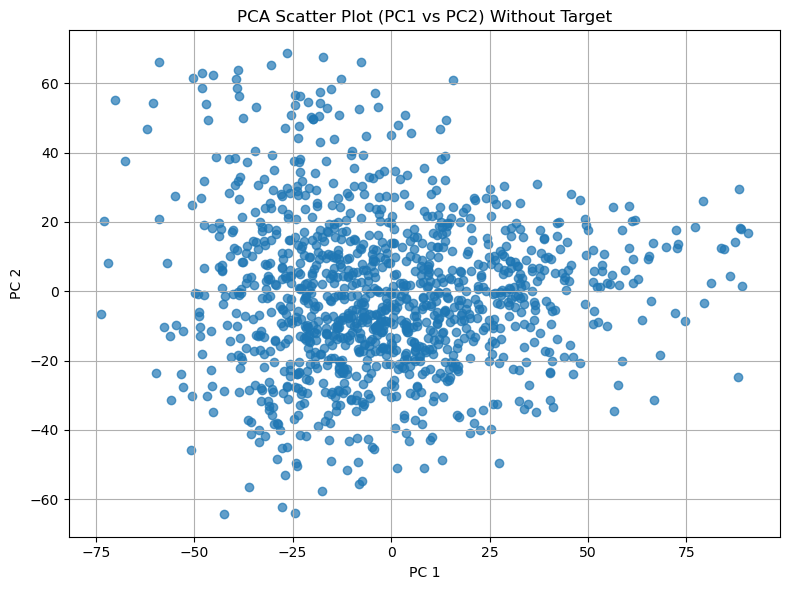

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(df_clean['PC_1'], df_clean['PC_2'], alpha=0.7)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA Scatter Plot (PC1 vs PC2) Without Target")
plt.grid(True)
plt.tight_layout()
plt.show()
